# La transition vers la voiture électrique en France
### Statistiques descriptives à l'échelle des communes de France métropolitaine

> **Mode d'emploi.** Ouvrir ce notebook à la racine du dépôt. Les fichiers de données sont à placer dans `data/raw/` (liste et liens dans le README). Le classeur AAV est indispensable : il sert de référentiel des communes. Les autres sources sont facultatives : si l'une manque, les analyses qui en dépendent sont simplement sautées.

## Introduction

**Contexte.** La voiture 100 % électrique progresse rapidement dans les ventes de voitures neuves. Le parc automobile, lui, ne se renouvelle que lentement : chaque année, les voitures neuves ne représentent qu'une petite partie des voitures en circulation. La transition se lit donc d'abord dans les immatriculations, puis, avec retard, dans le parc. Elle n'a aucune raison d'être homogène sur le territoire : le prix d'achat, la possibilité de recharger chez soi ou sur une borne publique et les distances parcourues au quotidien varient fortement d'une commune à l'autre.

**Problématique.** *Comment la part des voitures 100 % électriques varie-t-elle entre les communes de France métropolitaine, et comment ces écarts se répartissent-ils selon le niveau de vie, la position dans les aires d'attraction des villes et l'offre de recharge publique ?*

**Hypothèses.**
- **H1 – Niveau de vie.** Une voiture électrique coûte plus cher à l'achat qu'une voiture thermique équivalente : on s'attend à une part plus élevée dans les communes aisées.
- **H2 – Territoire.** Les pôles urbains et leurs couronnes concentrent l'offre de véhicules et les usages adaptés à l'électrique (trajets réguliers, maisons individuelles où l'on peut recharger à domicile dans les couronnes). On s'attend à une part plus faible dans les communes hors de l'influence des villes.
- **H3 – Recharge publique.** On s'attend à une part plus élevée là où l'offre de recharge est plus dense. Le sens de la relation reste ambigu : les bornes peuvent attirer les voitures électriques autant que s'installer là où elles sont déjà nombreuses.

**Données.**

| Source | Producteur | Ce qu'on en tire |
|---|---|---|
| Parc de véhicules par commune | SDES | voitures particulières au 1er janvier 2026, dont électriques |
| Immatriculations par commune (neuf, occasion) | SDES | voitures immatriculées en 2025, dont électriques |
| Zonage en aires d'attraction des villes | Insee | liste des communes (référentiel), position et taille de l'aire |
| Filosofi 2023 | Insee | niveau de vie médian de la commune |
| Populations de référence 2023 | Insee | population municipale |
| Base permanente des équipements 2025 | Insee | gares et équipements de transport |
| Base consolidée IRVE | transport.data.gouv.fr | points de recharge ouverts au public |
| Contours des communes 2026 | Etalab | carte et rattachement des bornes par leurs coordonnées |

**Méthode.** L'unité d'observation est la **commune**. La part électrique d'une commune est le nombre de voitures particulières 100 % électriques divisé par le nombre total de voitures particulières ; les hybrides rechargeables restent au dénominateur. Pour comparer des groupes de communes, on utilise deux résumés qui répondent à deux questions différentes :
- la **médiane des parts communales** : la part de la commune « du milieu » du groupe, où chaque commune pèse autant ;
- la **part agrégée** : toutes les voitures électriques du groupe divisées par toutes ses voitures, où les communes très équipées en voitures pèsent davantage.

Les résultats sont **descriptifs** : ils montrent des écarts entre groupes de communes, pas l'effet causal d'une variable sur l'achat de voitures électriques.

## Sommaire

0. [Mise en place et vérification des fichiers](#mise-en-place)
1. [Référentiel communal](#referentiel)
2. [Préparation des sources](#preparation)
3. [Jointures et couverture des sources](#jointures)
4. [Indicateurs et contrôles](#indicateurs)
5. [Tableaux et graphiques](#resultats)
   - [Le marché du neuf](#neuf)
   - [Niveau de vie et territoire croisés](#croisement)
   - [Présence d'une gare](#gare)
6. [Export de la base communale](#export)
7. [Conclusion](#conclusion)

<a id="mise-en-place"></a>
## 0. Mise en place et vérification des fichiers

Cette cellule charge les bibliothèques et les modules du projet (dossier `src/`). Elle construit ensuite le dictionnaire `disponible`, qui indique pour chaque source si son fichier est bien présent dans `data/raw/`. Toute la suite s'appuie sur ce dictionnaire : une analyse n'est lancée que si les fichiers dont elle a besoin sont là.

Le classeur AAV est le seul fichier obligatoire : sans lui, il n'y a pas de liste de communes, et la cellule s'arrête avec un message explicite.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, preparation, fusion, indicateurs, graphiques

disponible = {nom: preparation.chemin_brut(nom).is_file() for nom in config.FICHIERS}
display(pd.DataFrame([
    {"source": nom, "fichier": fichier, "présent": disponible[nom]}
    for nom, fichier in config.FICHIERS.items()
]))
if not disponible["aav"]:
    raise FileNotFoundError(f"Classeur AAV manquant : {preparation.chemin_brut('aav')}")


,source,fichier,présent
0,parc,Donnees-sur-le-parc-de-vehicules-au-niveau-com...,True
1,neuf,Immatriculations-de-vehicules-achetes-neufs-au...,False
2,occasion,Immatriculations-de-vehicules-achetes-doccasio...,False
3,aav,AAV2020_au_01-01-2026.xlsx,True
4,filosofi,DS_FILOSOFI_CC_2023_data.csv,True
5,irve,consolidation-etalab-schema-irve-statique-v-2_...,True
6,bpe,DS_BPE_2025_data.csv,False
7,population,DS_POPULATIONS_REFERENCE_2023_data.csv,True
8,contours,communes-50m.geojson,True


**Lecture.** La colonne `présent` doit valoir `True` pour chaque source utilisée. Si une ligne affiche `False` alors que le fichier a été téléchargé, c'est en général que son nom ne correspond pas exactement à celui indiqué dans `src/config.py` (dictionnaire `FICHIERS`).

<a id="referentiel"></a>
## 1. Référentiel communal

Le référentiel est la liste des communes de France métropolitaine (Corse comprise) dans la géographie au 1er janvier 2026, tirée du zonage en aires d'attraction des villes. Toutes les autres sources y seront rattachées par le code commune. Pour chaque commune, on récupère sa **position dans l'aire** (pôle, couronne ou hors attraction), la **taille de l'aire**, son département et sa région.

In [2]:
referentiel = preparation.preparer_aav()
print(f"{len(referentiel):,} communes dans le référentiel.")


34,746 communes dans le référentiel.


<a id="preparation"></a>
## 2. Préparation des sources

Chaque source est ramenée au même format : **une ligne par commune**, identifiée par `code_commune`. C'est ce qui permet ensuite de toutes les joindre.

- **Parc et immatriculations (SDES)** : on garde les voitures particulières, puis on additionne pour chaque commune toutes les voitures, les électriques, et les mêmes pour les seuls ménages. Pour le parc, on lit la colonne du 1er janvier 2026 ; pour les immatriculations, celle de l'année 2025. Les arrondissements de Paris, Lyon et Marseille sont regroupés au niveau de la commune.
- **Filosofi, population, BPE (Insee)** : on garde les lignes communales et l'indicateur utile (niveau de vie médian, population municipale, nombre de gares et d'équipements de transport).
- **IRVE** : on supprime les points de charge en double, puis on rattache chaque point à une commune, d'abord par son code Insee, ensuite par ses coordonnées géographiques s'il n'a pas de code valide.

In [3]:
tables = {}

for nom in ("parc", "neuf", "occasion"):
    if disponible[nom]:
        est_parc = nom == "parc"
        colonne = f"PARC_{config.ANNEE_PARC}" if est_parc else f"IMMAT_{config.ANNEE_IMMAT}"
        brut = preparation.lire_fichier_sdes(nom, [colonne])
        tables[nom] = preparation.preparer_vehicules(
            brut, colonne,
            config.ELEC_PARC if est_parc else config.ELEC_IMMAT,
            config.MENAGE_PARC if est_parc else config.MENAGE_IMMAT,
            nom,
        )

for nom, preparer in (
    ("filosofi", preparation.preparer_filosofi),
    ("population", preparation.preparer_population),
    ("bpe", preparation.preparer_bpe),
):
    if disponible[nom]:
        tables[nom] = preparer()

if disponible["irve"]:
    tables["irve"], points = preparation.preparer_irve(referentiel["code_commune"])
    display(points["rattachement"].value_counts())


rattachement
code Insee     78942
coordonnées    69741
non apparié      858
Name: count, dtype: int64

**Lecture.** Le tableau indique comment les points de recharge ont été rattachés : par leur code Insee, par leurs coordonnées (quand le code manquait ou n'était pas valide), ou pas du tout (« non apparié »). Seuls les points rattachés à une commune sont comptés dans la suite.

<a id="jointures"></a>
## 3. Jointures et couverture des sources

Chaque table est ajoutée au référentiel par une **jointure à gauche** sur le code commune : toutes les communes du référentiel sont conservées, qu'elles aient ou non une donnée dans la source. Le code vérifie à chaque étape que la source n'a qu'une ligne par commune et que le nombre de communes ne change pas.

Le **tableau de couverture** résume chaque jointure : le nombre de communes appariées, le nombre de communes sans donnée, et le nombre de codes de la source absents du référentiel.

In [4]:
if tables:
    base, couverture = fusion.construire_base(referentiel, tables)
    display(couverture)
else:
    base = referentiel.copy()
    print("Aucune source à joindre au référentiel.")


,communes du référentiel,communes appariées,communes sans donnée,codes de la source hors référentiel
source,,,,
parc,34746,34742,4,230
filosofi,34746,34744,2,24
population,34746,34746,0,112
irve,34746,10513,24233,0


**Lecture.** Les codes « hors référentiel » sont attendus : il s'agit surtout des départements d'outre-mer et des codes fictifs du SDES (un numéro de département suivi de `000`) utilisés quand la commune du véhicule est inconnue. Les communes « sans donnée » sont peu nombreuses ; pour Filosofi, il s'agit des communes dont le niveau de vie est couvert par le secret statistique.

<a id="indicateurs"></a>
## 4. Indicateurs et contrôles

Cette cellule calcule les indicateurs à partir de la base communale :
- si une source est absente, ses colonnes sont créées vides, pour que les calculs suivants fonctionnent quand même ;
- **parts électriques** (en %) dans le parc, les immatriculations neuves et d'occasion, pour tous les utilisateurs et pour les seuls ménages. Une part reste manquante quand le dénominateur vaut 0 (par exemple une commune sans aucune immatriculation neuve en 2025) ;
- **indicateurs de recharge et de transport**, rapportés à la population ou au nombre de voitures électriques ;
- **groupes de niveau de vie** : les communes sont réparties en quartiles de niveau de vie médian, chaque groupe contenant à peu près le même nombre de communes ;
- **classes de recharge** : « aucun point recensé », puis trois tiers (faible, moyenne, élevée) selon la densité de points parmi les communes qui en ont.

La dernière ligne lance des **contrôles de cohérence** sur la base.

In [ ]:
colonnes_sources = [
    f"vp_{nom}{suffixe}"
    for nom in ("parc", "neuf", "occasion")
    for suffixe in ("", "_elec", "_men", "_elec_men")
] + [
    "niveau_vie_median", "population", "nb_points", "nb_points_rapides",
    "nb_gares", "nb_equip_transport",
]

for colonne in colonnes_sources:
    if colonne not in base:
        base[colonne] = float("nan")

base = indicateurs.calculer_indicateurs(base, irve_exhaustif=disponible["irve"])
base["gare"] = base["gare"].where(base["nb_gares"].notna())
base, bornes_revenu = indicateurs.ajouter_groupes_revenu(base)
base = indicateurs.ajouter_classes_recharge(base)
display(indicateurs.controler_base(base))


,effectifs négatifs,électriques > total,"parts hors [0, 100]",parts indéfinies
table,,,,
parc,0,0,0,4
neuf,0,0,0,34746
occasion,0,0,0,34746


**Lecture.** Les trois premières colonnes doivent valoir 0 : aucun effectif négatif, jamais plus de voitures électriques que de voitures, aucune part en dehors de 0-100 %. La dernière colonne compte les parts indéfinies, c'est-à-dire les communes dont le dénominateur vaut 0 : elles ne sont pas des erreurs, mais elles sont exclues des comparaisons.

<a id="resultats"></a>
## 5. Tableaux et graphiques

Cette section présente les résultats, chacun suivi de son interprétation :
1. le **tableau de synthèse par région** : chaque indicateur est calculé sur le total de la région (somme des numérateurs divisée par la somme des dénominateurs), ce qui permet de comparer des régions de tailles très différentes ; la dernière ligne donne la France métropolitaine ;
2. les **bornes des quartiles de niveau de vie**, en euros par an ;
3. pour chacune des trois comparaisons (position dans l'aire d'attraction, niveau de vie, offre de recharge), un **tableau résumé** puis un **graphique** ;
4. la **carte communale** de la part électrique du parc, si les contours des communes sont disponibles.
5. trois **analyses complémentaires** : le marché du neuf comparé au parc, le croisement du niveau de vie et du territoire, et la présence d'une gare.

In [ ]:
# Tableau de synthèse par région (dernière ligne : France métropolitaine)
display(indicateurs.tableau_synthese(base))

,nb_communes,part VE parc (%),points de charge,points pour 100 VE,points pour 1 000 hab.
region,,,,,
Auvergne-Rhône-Alpes,4025,3.62,17284.0,9.39,2.11
Bourgogne-Franche-Comté,3685,2.56,5670.0,12.19,2.02
Bretagne,1202,3.04,6510.0,9.66,1.89
Centre-Val de Loire,1754,2.85,6308.0,13.50,2.44
Corse,360,4.99,742.0,6.63,2.09
Grand Est,5115,3.31,14406.0,12.59,2.59
Hauts-de-France,3782,3.29,13246.0,11.36,2.21
Normandie,2644,3.29,8649.0,12.52,2.58
Nouvelle-Aquitaine,4293,3.01,13452.0,11.07,2.19


**Interprétation.** En France métropolitaine, 3,56 % des voitures particulières en circulation au 1er janvier 2026 sont 100 % électriques. Les écarts entre régions sont nets : la part dépasse 4,4 % en Corse (4,99 %), en Île-de-France (4,76 %) et en Provence-Alpes-Côte d'Azur (4,43 %), alors qu'elle reste sous 3 % en Bourgogne-Franche-Comté (2,56 %) et en Centre-Val de Loire (2,85 %). Elle est donc presque deux fois plus élevée en Corse qu'en Bourgogne-Franche-Comté.

L'offre de recharge publique varie beaucoup moins. Rapportée à la population, elle va de 1,86 point de charge pour 1 000 habitants en Pays de la Loire à 2,59 dans le Grand Est (2,25 en moyenne). Rapportée aux voitures électriques, elle est même souvent **plus élevée là où ces voitures sont rares** : 13,5 points pour 100 voitures électriques en Centre-Val de Loire et 12,2 en Bourgogne-Franche-Comté, contre 6,6 en Corse. À l'échelle des régions, une faible part électrique ne va donc pas de pair avec une offre de bornes plus faible par voiture électrique.

In [ ]:
# Bornes des quartiles de niveau de vie médian communal (euros par an)
if bornes_revenu is not None:
    display(bornes_revenu)

array([12420., 24090., 25780., 27830., 62730.])

**Interprétation.** Ces valeurs découpent les communes en quatre groupes de même effectif selon leur niveau de vie médian annuel : de 12 420 à 24 090 € (Q1), de 24 090 à 25 780 € (Q2), de 25 780 à 27 830 € (Q3) et de 27 830 à 62 730 € (Q4). Les deux groupes du milieu sont très resserrés (environ 1 700 et 2 000 € d'écart entre leurs bornes), alors que Q1 s'étend sur près de 12 000 € et Q4 sur près de 35 000 € : les différences de niveau de vie entre communes se concentrent aux deux extrémités, surtout en haut de la distribution.

Ces quartiles portent sur les **communes**, pas sur les ménages : une grande ville compte pour une commune, comme un village.

**Comment lire les tableaux et les graphiques.**
- `nb_communes` : nombre de communes du groupe ayant une part calculable.
- `q1`, `mediane`, `q3` : premier quartile, médiane et troisième quartile des parts communales. L'écart entre `q1` et `q3` montre la dispersion à l'intérieur du groupe.
- `vp_elec`, `vp_total` et `part_agregee` : nombre total de voitures électriques, nombre total de voitures, et part électrique de l'ensemble du groupe.
- Sur les graphiques, la **barre** représente la part agrégée du groupe et le **losange** la part de la commune médiane.

Quand barre et losange divergent, c'est que les communes qui comptent beaucoup de voitures (souvent les plus peuplées) n'ont pas la même part électrique que la commune typique du groupe. Les deux lectures sont justes, mais elles ne répondent pas à la même question : il faut toujours préciser laquelle on commente.

In [ ]:
graphiques.appliquer_style()


def resumer(groupe):
    """Tableau résumé d'un regroupement de communes, ou None s'il n'est pas disponible."""
    if groupe not in base:
        return None
    resume = indicateurs.resume_par_groupe(base, groupe)
    return None if resume.empty else resume


def tracer(resume, groupe, libelle):
    """Graphique en barres associé au tableau résumé."""
    if resume is not None:
        graphiques.tracer_barres(
            resume, f"Part électrique du parc · {libelle}",
            f"parc_{groupe}", label_groupe=libelle, trier=False,
        )
        plt.show()

In [ ]:
resume_position = resumer("position_aav")
if resume_position is not None:
    display(resume_position)

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
position_aav,,,,,,,
Pôle,1713,2.20,2.87,3.75,629594.0,16737786.0,3.76
Couronne,24156,1.83,2.81,3.99,687730.0,19248811.0,3.57
Hors attraction,8873,1.00,1.92,2.94,71700.0,3014655.0,2.38


**Interprétation.** Les communes situées hors de l'attraction des villes ont nettement moins de voitures électriques : 1,92 % pour la commune médiane, contre 2,81 % dans les couronnes et 2,87 % dans les pôles, soit près d'un point d'écart. Entre pôles et couronnes, la commune médiane est presque identique.

Le nombre de communes ne reflète pas leur poids dans le parc : les 1 713 communes des pôles rassemblent 16,7 millions de voitures, presque autant que les 24 156 communes de couronne (19,2 millions), alors que les 8 873 communes hors attraction n'en comptent que 3 millions. La dispersion est plus forte dans les couronnes (de 1,83 % à 3,99 % entre le premier et le troisième quartile) que dans les pôles (de 2,20 % à 3,75 %).

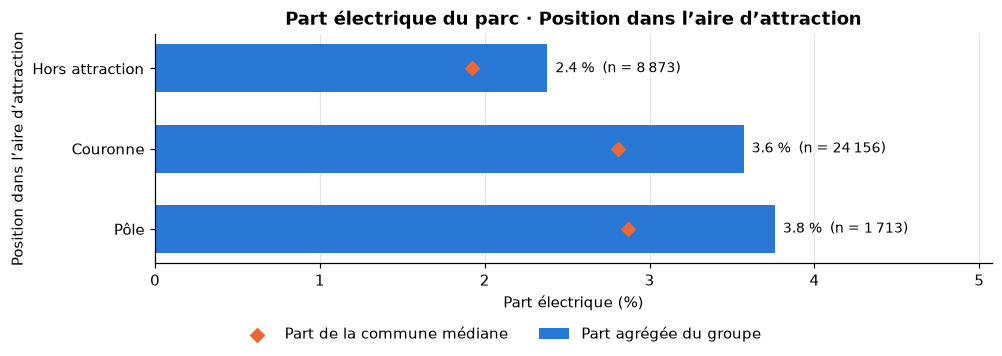

In [ ]:
tracer(resume_position, "position_aav", "Position dans l’aire d’attraction")

**Interprétation.** Dans les trois groupes, la barre (part agrégée) dépasse le losange (commune médiane) : les communes qui comptent beaucoup de voitures ont une part électrique plus élevée que la commune typique de leur groupe. L'écart est le plus grand dans les pôles (3,76 % contre 2,87 %), où les grandes villes pèsent lourd dans le total.

Quelle que soit la mesure, le classement est le même : les communes hors attraction sont loin derrière, et les pôles légèrement devant les couronnes. Ce résultat va dans le sens de l'hypothèse H2, sans permettre de trancher entre ses explications possibles (distances parcourues, type de logement, offre de véhicules, niveau de vie).

In [ ]:
resume_revenu = resumer("groupe_revenu")
if resume_revenu is not None:
    display(resume_revenu)

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
groupe_revenu,,,,,,,
Q1 (plus modestes),7701,1.22,1.93,2.68,335314.0,11713531.0,2.86
Q2,7698,1.57,2.34,3.13,222242.0,7588756.0,2.93
Q3,7688,2.04,2.86,3.74,279918.0,8030868.0,3.49
Q4 (plus aisées),7683,2.97,3.97,5.08,547416.0,11465819.0,4.77


**Interprétation.** La part électrique de la commune médiane augmente à chaque quartile : 1,93 % (Q1), 2,34 % (Q2), 2,86 % (Q3) et 3,97 % (Q4). Elle est donc environ deux fois plus élevée dans le quart des communes les plus aisées que dans le quart des plus modestes. La plus forte hausse se produit entre Q3 et Q4 (+1,1 point), alors que les niveaux de vie de Q2 et de Q3 sont très proches. C'est aussi dans Q4 que les communes sont les plus dispersées (de 2,97 % à 5,08 % entre le premier et le troisième quartile).

Le poids des groupes dans le parc est inégal : Q1 et Q4 comptent chacun environ 11,5 millions de voitures, contre 7,6 et 8 millions pour Q2 et Q3.

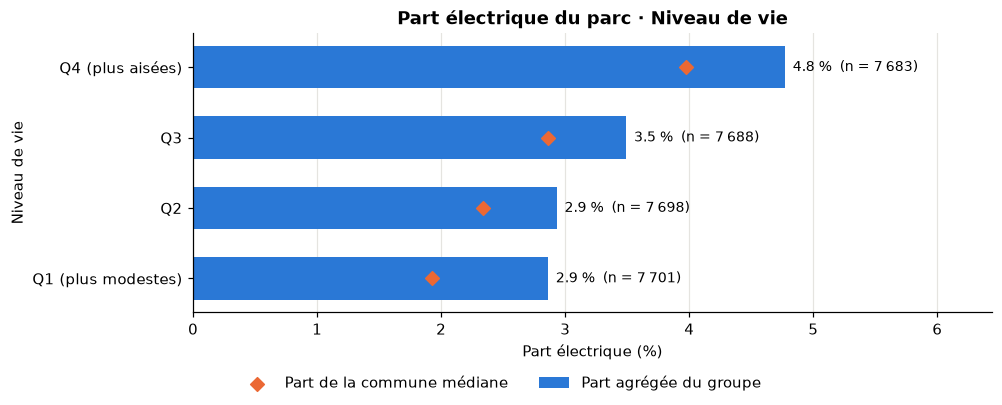

In [ ]:
tracer(resume_revenu, "groupe_revenu", "Niveau de vie")

**Interprétation.** Le graphique confirme la progression avec le niveau de vie, ce qui soutient l'hypothèse H1. Mais la barre et le losange ne racontent pas la même chose en bas de l'échelle : pour Q1, la part agrégée (2,86 %) est nettement supérieure à la médiane (1,93 %) et presque égale à celle de Q2 (2,93 %).

Le premier quartile contient en effet de grandes villes au niveau de vie médian modeste, dont la part électrique dépasse largement celle de la commune médiane du groupe : Marseille (4,2 %), Nice (4,8 %) ou Lille (4,5 %). Comme elles concentrent beaucoup de voitures, elles tirent la part agrégée vers le haut. En part agrégée, l'écart se concentre donc surtout dans le quart le plus aisé (4,77 %).

In [ ]:
resume_recharge = resumer("classe_recharge")
if resume_recharge is not None:
    display(resume_recharge)

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
classe_recharge,,,,,,,
Aucun point recensé,24229,1.37,2.38,3.54,249821.0,8420318.0,2.97
Faible,3507,2.42,3.13,4.11,470566.0,13299642.0,3.54
Moyenne,3502,2.15,3.00,4.03,477152.0,12353879.0,3.86
Élevée,3504,1.89,2.90,4.19,191485.0,4927413.0,3.89


**Interprétation.** Les 24 229 communes sans aucun point de recharge public rattaché (70 % des communes, mais seulement 8,4 millions de voitures) ont la part électrique la plus faible : 2,38 % pour la commune médiane, contre 2,90 % à 3,13 % dans les communes équipées.

Parmi les communes équipées, la médiane ne progresse pas avec la densité de bornes : elle baisse même légèrement, de 3,13 % (densité faible) à 2,90 % (densité élevée). La part agrégée, elle, augmente de 3,54 % à 3,89 %. Le groupe de densité élevée réunit surtout de petites communes : environ 1 400 voitures en moyenne par commune, contre près de 3 800 dans le groupe de densité faible. Dans une petite commune, quelques bornes suffisent à faire monter le nombre de points pour 1 000 habitants.

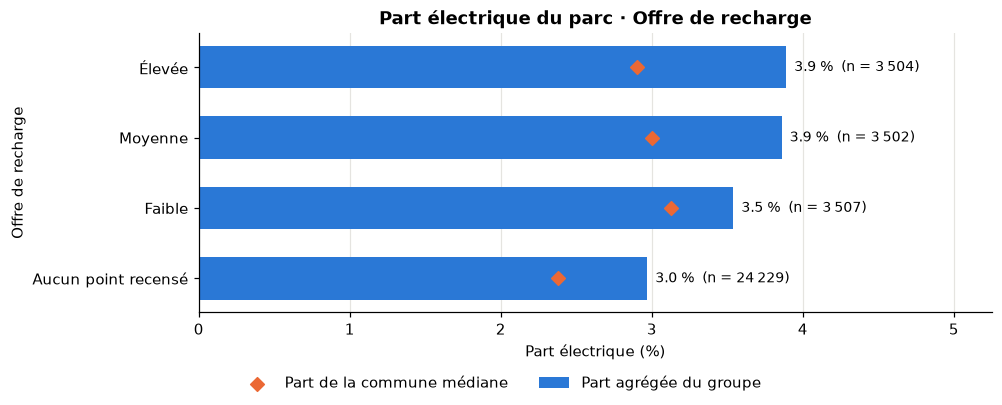

In [ ]:
tracer(resume_recharge, "classe_recharge", "Offre de recharge")

**Interprétation.** La différence nette se situe entre les communes sans borne et les communes équipées, plus qu'entre les niveaux de densité. Ce résultat va dans le sens de l'hypothèse H3, avec deux réserves importantes :
- le lien peut aller dans les deux sens : les bornes s'installent aussi là où les voitures électriques sont déjà nombreuses ;
- les communes équipées sont beaucoup plus grandes (près de 2 900 voitures en moyenne par commune, contre environ 350 dans les communes sans borne) et plus souvent urbaines, ce qui recoupe les écarts déjà observés selon la position dans l'aire d'attraction.

Enfin, l'offre de recharge est mesurée en octobre 2026 et le parc au 1er janvier 2026 : les deux dates ne coïncident pas.

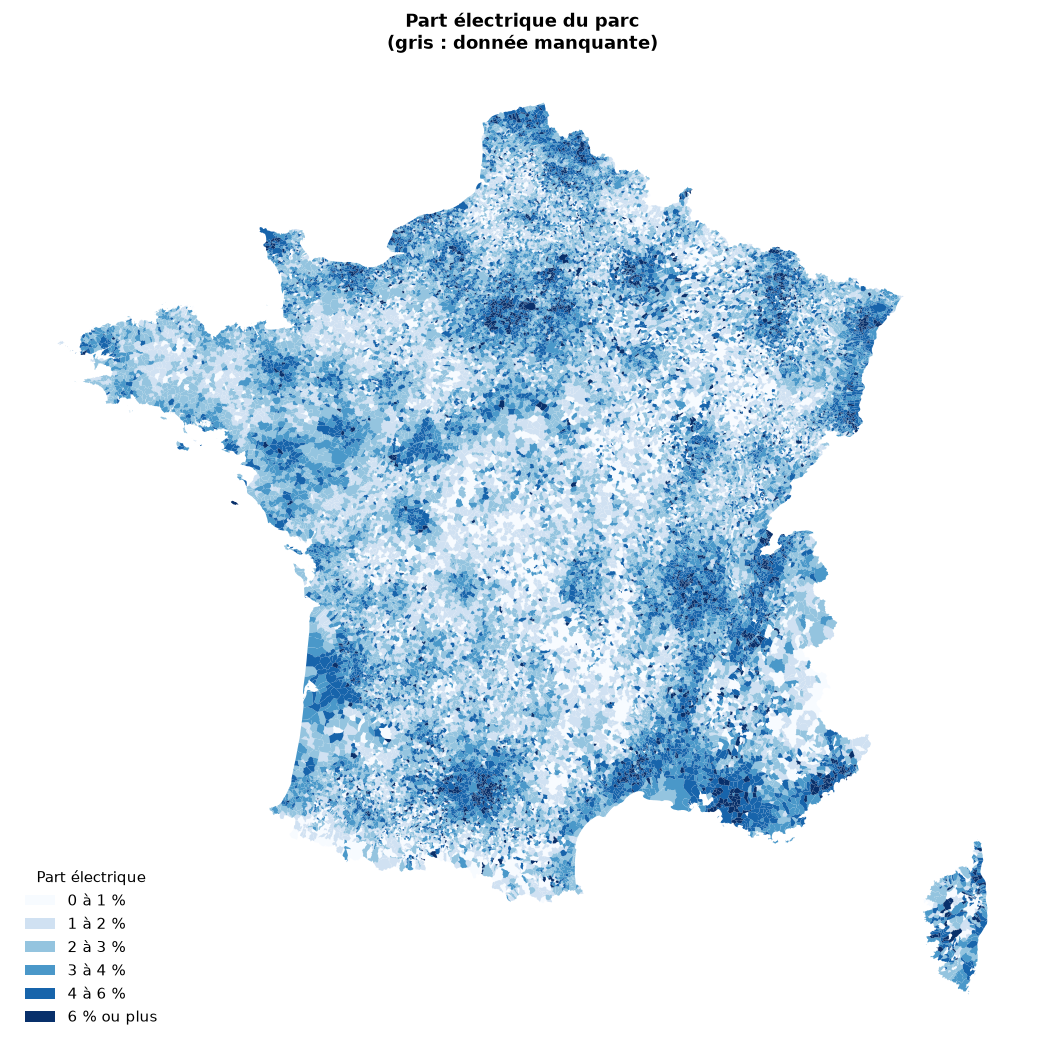

In [ ]:
if disponible["contours"] and base["part_parc"].notna().any():
    graphiques.tracer_carte(base, "part_parc", "Part électrique du parc", "carte_communes")
    plt.show()

**Interprétation.** La carte fait apparaître une géographie nette. Les parts les plus élevées (bleu foncé) se concentrent autour des grandes agglomérations (Île-de-France, Lyon et le sillon alpin, Bordeaux, Toulouse, Nantes, Lille), sur le littoral méditerranéen, en Alsace et en Corse. Les parts les plus faibles (teintes claires) dominent dans une large bande rurale qui traverse le pays du nord-est au sud-ouest en passant par le centre, et qui rappelle la « diagonale des faibles densités ».

La carte est aussi très morcelée : des communes voisines peuvent avoir des parts très différentes. Cela reflète en partie les petits effectifs des communes rurales, où quelques voitures électriques suffisent à faire varier la part de plusieurs points.

<a id="neuf"></a>
### Le marché du neuf : la transition en train de se faire

Le parc est un **stock** : il change lentement. Les immatriculations neuves sont un **flux** : elles montrent ce que l'on achète aujourd'hui, donc la direction que prend le parc. Cette partie compare les deux, d'abord pour la France métropolitaine, puis selon le territoire et le niveau de vie.

Pour les voitures neuves, on retient les **ménages** (personnes physiques). Plus de la moitié des voitures neuves sont immatriculées par des entreprises ou des loueurs, à l'adresse de leur établissement : les compter brouillerait la géographie des achats.

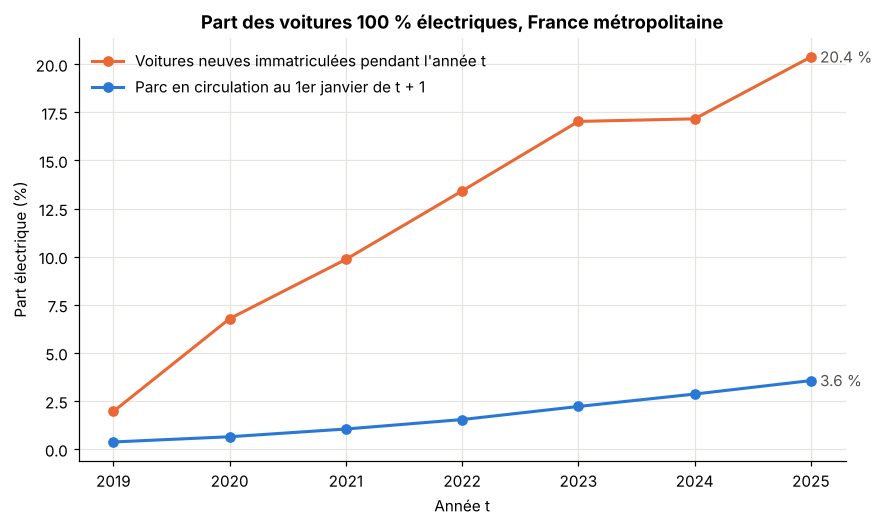

In [ ]:
# Séries annuelles France métropolitaine : parc au 1er janvier et immatriculations neuves
if disponible["parc"] and disponible["neuf"]:
    brut_parc = preparation.lire_fichier_sdes("parc", [f"PARC_{a}" for a in range(2011, config.ANNEE_PARC + 1)])
    serie_parc = preparation.serie_metropole(brut_parc, "PARC_", config.ELEC_PARC)
    brut_neuf = preparation.lire_fichier_sdes("neuf", [f"IMMAT_{a}" for a in range(2010, config.ANNEE_IMMAT + 1)])
    serie_neuf = preparation.serie_metropole(brut_neuf, "IMMAT_", config.ELEC_IMMAT)
    del brut_parc, brut_neuf   # libère la mémoire

    graphiques.tracer_tendance(serie_parc, serie_neuf, debut=2019, fin=2025)
    plt.show()

**Interprétation.** La part des voitures électriques dans les ventes de voitures neuves a été multipliée par dix en six ans : 2,0 % en 2019, 20,4 % en 2025. La progression a été rapide jusqu'en 2023 (17,0 %), puis a marqué une pause en 2024 (17,2 %) avant de repartir. Dans le parc, la hausse est régulière mais beaucoup plus lente : 0,4 % au 1er janvier 2020, 3,6 % au 1er janvier 2026, soit 1,4 million de voitures électriques sur 39 millions.

Cet écart vient du rythme de renouvellement du parc : les voitures neuves d'une année ne représentent qu'environ 4 % des voitures en circulation (1,6 million pour 39 millions). Même quand une voiture neuve sur cinq est électrique, le parc ne suit que lentement.

In [ ]:
def comparer_parc_neuf(groupe):
    """Part électrique agrégée dans le parc et dans les immatriculations neuves des ménages."""
    parc = indicateurs.resume_par_groupe(base, groupe, "parc")["part_agregee"]
    neuf = indicateurs.resume_par_groupe(base, groupe, "neuf", menages=True)["part_agregee"]
    tableau = pd.DataFrame({
        "parc au 01/01/2026 (%)": parc,
        "immatriculations neuves 2025, ménages (%)": neuf,
    })
    tableau["écart (points)"] = tableau.iloc[:, 1] - tableau.iloc[:, 0]
    return tableau.round(2)


if disponible["neuf"]:
    neuf_position = comparer_parc_neuf("position_aav")
    display(neuf_position)

,parc au 01/01/2026 (%),"immatriculations neuves 2025, ménages (%)",écart (points)
position_aav,,,
Pôle,3.76,18.42,14.66
Couronne,3.57,23.99,20.42
Hors attraction,2.38,21.13,18.75


**Interprétation.** La hiérarchie s'inverse entre le parc et le neuf. Dans le parc, les pôles sont devant (3,76 %) et les communes hors attraction loin derrière (2,38 %). Parmi les voitures neuves achetées par les ménages en 2025, ce sont au contraire les **couronnes** qui ont la part électrique la plus élevée (23,99 %), devant les communes hors attraction (21,13 %) et les pôles (18,42 %). Le même classement s'observe en comptant tous les acheteurs, entreprises comprises (22,2 % en couronne, 20,1 % hors attraction, 19,2 % dans les pôles).

Une piste d'explication est le logement : en couronne et dans les communes rurales, les ménages vivent plus souvent en maison individuelle, où l'on peut installer une prise de recharge, alors qu'en immeuble la recharge à domicile est plus difficile. Nos données ne permettent pas de le vérifier directement.

In [ ]:
if disponible["neuf"] and bornes_revenu is not None:
    neuf_revenu = comparer_parc_neuf("groupe_revenu")
    display(neuf_revenu)

,parc au 01/01/2026 (%),"immatriculations neuves 2025, ménages (%)",écart (points)
groupe_revenu,,,
Q1 (plus modestes),2.86,18.61,15.75
Q2,2.93,21.28,18.35
Q3,3.49,22.25,18.76
Q4 (plus aisées),4.77,23.34,18.57


**Interprétation.** Dans le neuf aussi, la part électrique augmente avec le niveau de vie de la commune : de 18,61 % dans le premier quartile à 23,34 % dans le dernier. Mais l'écart relatif est bien plus faible que dans le parc : dans le neuf, la part du quart le plus aisé n'est que 1,25 fois celle du quart le plus modeste, contre 1,67 fois dans le parc. De Q2 à Q4, les parts du neuf sont même proches (de 21,28 % à 23,34 %).

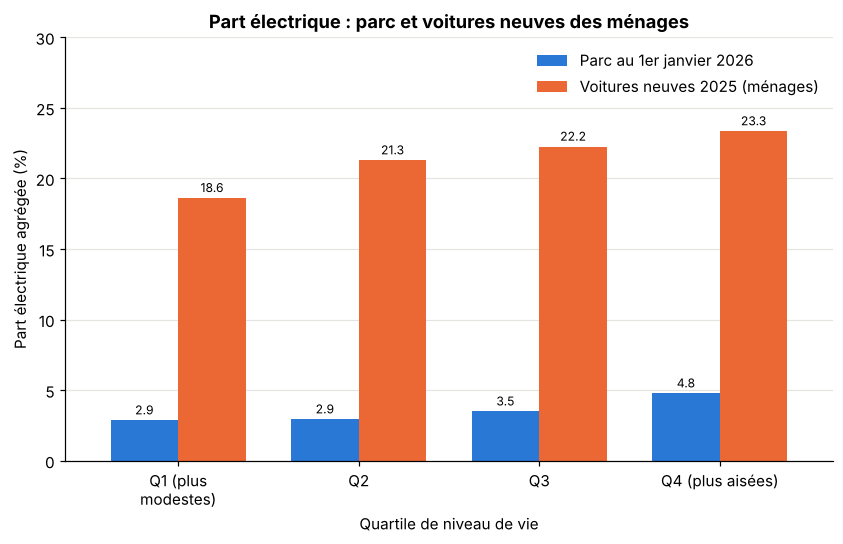

In [ ]:
if disponible["neuf"] and bornes_revenu is not None:
    a_tracer = neuf_revenu.iloc[:, :2]
    a_tracer.columns = ["Parc au 1er janvier 2026", "Voitures neuves 2025 (ménages)"]
    graphiques.tracer_barres_groupees(
        a_tracer, "Part électrique : parc et voitures neuves des ménages",
        "parc_neuf_revenu", label_x="Quartile de niveau de vie", label_legende="",
    )
    plt.gca().set_ylim(0, 30)   # laisse de la place à la légende au-dessus des barres
    plt.show()

**Interprétation.** Le graphique rend visible le changement d'échelle : dans tous les quartiles, entre une voiture neuve sur cinq et près d'une sur quatre achetée par un ménage est électrique, alors que le parc n'en compte encore que 3 à 5 %. Le resserrement des écarts dans le neuf suggère que la diffusion gagne les communes plus modestes, ce qui pourrait réduire peu à peu les écarts observés dans le parc. Une piste, à vérifier, est le rôle des aides publiques ciblées sur les ménages modestes, comme le leasing social.

Ces écarts sont mesurés entre **communes** et non entre ménages : ils ne disent pas qui, dans une commune donnée, achète une voiture électrique.

<a id="croisement"></a>
### Niveau de vie et territoire croisés

Les communes aisées sont plus souvent situées en couronne, et les communes modestes plus souvent hors attraction : l'écart de revenu observé plus haut pourrait donc refléter en partie un effet de territoire. Pour le vérifier, on croise les deux. Chaque case donne la part électrique agrégée du parc et le nombre de communes.

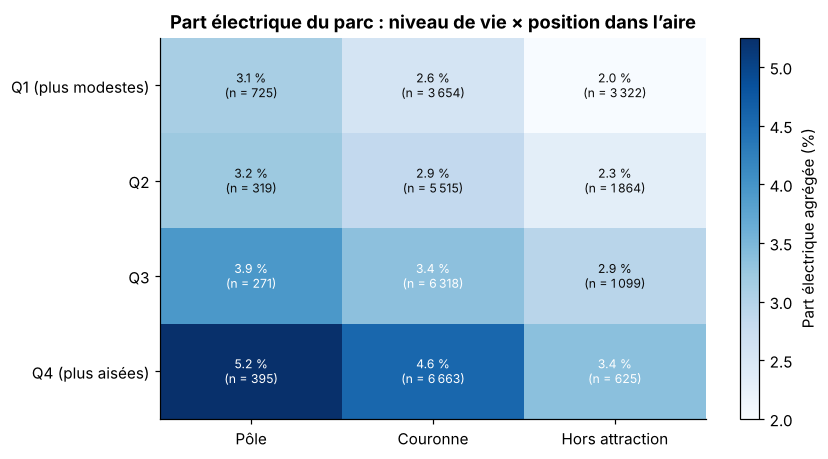

In [ ]:
# Part électrique agrégée du parc dans chaque case quartile de revenu x position dans l'aire
if bornes_revenu is not None:
    parts_croisees, n_croises = indicateurs.tableau_croise(base, "groupe_revenu", "position_aav", "parc")
    graphiques.tracer_matrice(
        parts_croisees, n_croises,
        "Part électrique du parc : niveau de vie × position dans l’aire",
        "matrice_revenu_position",
    )
    plt.show()

**Interprétation.** Les deux écarts se maintiennent quand on croise les variables. **À position égale**, la part augmente toujours avec le niveau de vie : de 3,1 % à 5,2 % dans les pôles, de 2,6 % à 4,6 % dans les couronnes, de 2,0 % à 3,4 % hors attraction. **À niveau de vie égal**, les pôles restent devant les couronnes, elles-mêmes devant les communes hors attraction. L'écart de revenu ne s'explique donc pas seulement par la localisation des communes aisées, et l'écart territorial pas seulement par le revenu. Les parts médianes de chaque case suivent les mêmes tendances.

La composition des groupes est très différente : les communes modestes sont souvent hors attraction (3 322 communes dans Q1), les communes aisées surtout en couronne (6 663 dans Q4). Les cases des pôles de Q2 et Q3 reposent sur relativement peu de communes (319 et 271) et sont à lire avec prudence.

<a id="gare"></a>
### Présence d'une gare

On compare la part électrique des communes avec et sans gare de voyageurs (BPE 2025), d'abord globalement, puis à position comparable dans l'aire d'attraction. Cette deuxième étape est nécessaire : les communes avec gare sont beaucoup plus peuplées (population médiane d'environ 3 500 habitants, contre environ 400 pour les communes sans gare).

In [ ]:
# Présence d'une gare de voyageurs dans la commune (BPE 2025)
if disponible["bpe"]:
    base["gare_libelle"] = pd.Categorical(
        base["gare"].map({1: "Avec gare", 0: "Sans gare"}),
        categories=["Sans gare", "Avec gare"], ordered=True,
    )
    display(indicateurs.resume_par_groupe(base, "gare_libelle"))

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
gare_libelle,,,,,,,
Sans gare,32201,1.56,2.56,3.74,775279.0,22575840.0,3.43
Avec gare,2541,2.17,2.90,3.79,613745.0,16425412.0,3.74


**Interprétation.** Les 2 541 communes avec gare ont une part électrique un peu plus élevée que les 32 201 autres : 2,90 % contre 2,56 % pour la commune médiane, et 3,74 % contre 3,43 % en part agrégée. Elles rassemblent pourtant beaucoup de voitures (16,4 millions, contre 22,6 millions pour toutes les communes sans gare) : ce sont souvent des communes plus peuplées et plus urbaines.

gare_libelle,Sans gare,Avec gare
position_aav,,
Pôle,962,751
Couronne,22631,1525
Hors attraction,8608,265


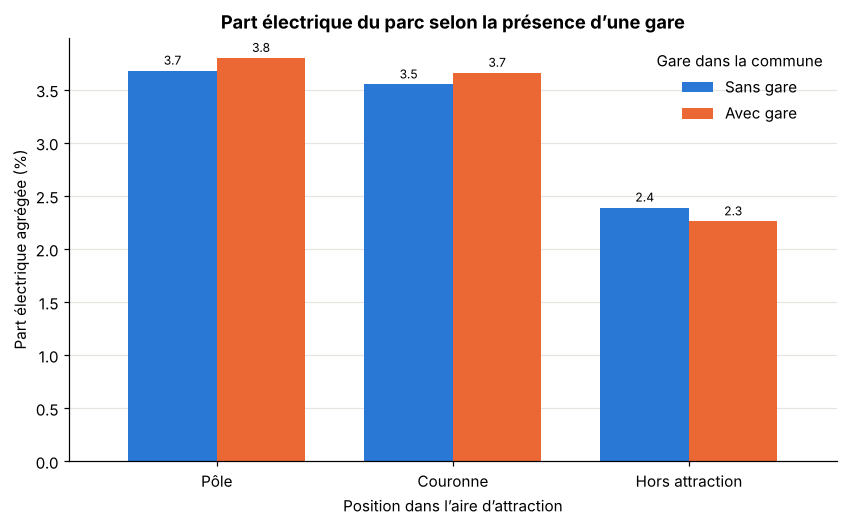

In [ ]:
# Même comparaison, à position dans l'aire d'attraction comparable
if disponible["bpe"]:
    parts_gare, n_gare = indicateurs.tableau_croise(base, "position_aav", "gare_libelle", "parc")
    display(n_gare)
    graphiques.tracer_barres_groupees(
        parts_gare, "Part électrique du parc selon la présence d’une gare",
        "parc_gare_position", label_x="Position dans l’aire d’attraction",
        label_legende="Gare dans la commune",
    )
    plt.show()

**Interprétation.** À position comparable, la présence d'une gare ne fait presque plus de différence : 3,80 % contre 3,68 % dans les pôles, 3,66 % contre 3,55 % dans les couronnes, et même un peu moins avec gare hors attraction (2,26 % contre 2,39 %). L'écart global vu plus haut vient donc surtout du fait que les communes avec gare sont plus urbaines. Le tableau des effectifs montre aussi que les gares sont rares hors attraction (265 communes).

Ce résultat ne permet pas de conclure que l'offre de transport collectif est sans lien avec l'électrification : la présence d'une gare ne dit rien de la fréquence des trains, ni de l'accès aux gares des communes voisines.

<a id="export"></a>
## 6. Export de la base communale

La base communale complète (une ligne par commune, avec toutes les sources et tous les indicateurs) est enregistrée dans `data/processed/base_communale.csv`. Elle permet de reprendre l'analyse sans relancer toute la préparation. Comme les données brutes, ce fichier reste sur l'ordinateur et n'est pas envoyé sur GitHub.

In [7]:
config.DOSSIER_PREP.mkdir(parents=True, exist_ok=True)
sortie = config.DOSSIER_PREP / "base_communale.csv"
base.to_csv(sortie, index=False)
print(sortie.relative_to(config.RACINE))


data\processed\base_communale.csv


<a id="conclusion"></a>

## 7. Conclusion

L’exécution enregistrée initialement a permis de constituer un référentiel de **34 746 communes de France métropolitaine**. Le fichier du parc automobile était absent et la part de voitures électriques restait indéfinie pour les 34 746 communes. Il était donc impossible de mesurer les écarts selon la position dans l’aire d’attraction, le niveau de vie ou l’offre de recharge.

Après ajout du parc automobile, de Filosofi, des données IRVE et de la population, la cellule ci-dessous résume les écarts observés. Elle compare les médianes des parts communales. Les différences mesurées sont descriptives et ne permettent pas d’établir un effet causal.

In [8]:
from IPython.display import Markdown

paragraphes = []
for groupe, titre, fichiers in (
    ("position_aav", "Position dans l’aire d’attraction", ("parc",)),
    ("groupe_revenu", "Niveau de vie", ("parc", "filosofi")),
    ("classe_recharge", "Offre de recharge", ("parc", "irve", "population")),
):
    manquants = [nom for nom in fichiers if not disponible[nom]]
    if manquants:
        paragraphes.append(f"**{titre}.** Comparaison indisponible. Sources manquantes : {', '.join(manquants)}.")
        continue

    resume = indicateurs.resume_par_groupe(base, groupe)
    if len(resume) < 2:
        paragraphes.append(f"**{titre}.** Moins de deux groupes disposent d’une part électrique calculable.")
        continue

    valeurs = " ; ".join(
        f"{nom} : {ligne['mediane']:.2f} % ({int(ligne['nb_communes'])} communes)"
        for nom, ligne in resume.iterrows()
    ).replace(".", ",")
    ecart = f"{resume['mediane'].max() - resume['mediane'].min():.2f}".replace(".", ",")
    paragraphes.append(
        f"**{titre}.** Parts médianes par groupe : {valeurs}. "
        f"L’écart entre la médiane la plus élevée et la plus faible est de {ecart} points de pourcentage."
    )

display(Markdown("\n\n".join(paragraphes)))


**Position dans l’aire d’attraction.** Parts médianes par groupe : Pôle : 2,87 % (1713 communes) ; Couronne : 2,81 % (24156 communes) ; Hors attraction : 1,92 % (8873 communes). L’écart entre la médiane la plus élevée et la plus faible est de 0,95 points de pourcentage.

**Niveau de vie.** Parts médianes par groupe : Q1 (plus modestes) : 1,93 % (7701 communes) ; Q2 : 2,34 % (7698 communes) ; Q3 : 2,86 % (7688 communes) ; Q4 (plus aisées) : 3,97 % (7683 communes). L’écart entre la médiane la plus élevée et la plus faible est de 2,04 points de pourcentage.

**Offre de recharge.** Parts médianes par groupe : Aucun point recensé : 2,38 % (24229 communes) ; Faible : 3,13 % (3507 communes) ; Moyenne : 3,00 % (3502 communes) ; Élevée : 2,90 % (3504 communes). L’écart entre la médiane la plus élevée et la plus faible est de 0,75 points de pourcentage.

## Conclusion
En France métropolitaine, les communes les plus aisées ont généralement une part plus élevée de voitures électriques dans leur parc automobile. La part médiane augmente à chaque quartile de niveau de vie, de 1,93 % dans le quart des communes les plus modestes à 3,97 % dans le quart le plus aisé. L’écart de 2,04 points de pourcentage est le plus marqué des trois comparaisons étudiées.

La part médiane est proche dans les pôles urbains (2,87 %) et dans leurs couronnes (2,81 %). Elle est plus faible dans les communes hors attraction (1,92 %), soit 0,95 point de moins que dans les pôles.

Pour la recharge publique, les communes auxquelles aucun point n’a été rattaché dans nos données ont la médiane la plus faible (2,38 %). Parmi les communes avec des points rattachés, la médiane passe de 3,13 % lorsque le nombre de points par habitant est faible à 3,00 % lorsqu’il est moyen et à 2,90 % lorsqu’il est élevé. En revanche, si on regroupe toutes les voitures de chaque catégorie, la part électrique augmente de 3,54 % à 3,89 % entre les groupes de faible et de forte densité. La médiane donne le même poids à chaque commune, tandis que la part agrégée donne davantage de poids aux communes qui ont plus de voitures.

Le rattachement par coordonnées a permis de localiser 69 741 points supplémentaires. Il reste 858 points non appariés, soit 0,57 % des points après dédoublonnage. Les résultats décrivent des écarts entre groupes de communes et ne permettent pas d’établir l’effet propre du niveau de vie, de la localisation ou de la recharge sur la part de voitures électriques.